## 2D Gaussian OCSMM-SHAP Basic Exp

In [1]:
from src.ocsmm.OneClassSMMClassifier import OneClassSMMClassifier
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
np.random.seed(20)

# Parameters
num_groups = 100
num_points_per_group = 30
num_features = 3  # Two Gaussian features + one label
num_normal = 97
num_anomalous = 3

# Generate data
dataset = []
for i in range(num_groups):
    if i < num_normal:
        label = np.random.choice([1, 2, 3])  
    else:
        label = np.random.choice([18, 19, 20]) 
    points = np.random.multivariate_normal(mean=[0, 0], cov=[[1, 0], [0, 1]], size=num_points_per_group)
    feature_3 = np.full((num_points_per_group, 1), label)  # Feature 3 as a column
    group_data = np.hstack([points, feature_3]) 
    dataset.append(group_data)

# Convert dataset into a 3D NumPy array
final_dataset = np.array(dataset)  

In [3]:
final_dataset

array([[[-9.50443117e-01,  1.50227571e+00,  3.00000000e+00],
        [ 2.12601055e+00,  2.49155430e-01,  3.00000000e+00],
        [-6.20642157e-01, -8.34532935e-01,  3.00000000e+00],
        ...,
        [-2.21909547e+00, -7.49404606e-01,  3.00000000e+00],
        [ 4.86063175e-01, -1.76752659e+00,  3.00000000e+00],
        [ 2.22710846e-01, -7.05439508e-01,  3.00000000e+00]],

       [[-5.48331454e-01,  2.97280923e-01,  3.00000000e+00],
        [-6.00914445e-01,  9.10865062e-01,  3.00000000e+00],
        [ 1.43127170e+00,  2.60349438e-01,  3.00000000e+00],
        ...,
        [ 6.83495390e-01,  9.26002960e-01,  3.00000000e+00],
        [ 2.27227061e-01, -1.96859016e-01,  3.00000000e+00],
        [-6.39854207e-01, -1.33643179e-02,  3.00000000e+00]],

       [[-3.14030161e-01, -9.55774320e-01,  1.00000000e+00],
        [ 4.41255095e-01, -2.07323620e-02,  1.00000000e+00],
        [ 4.15292839e-01, -6.92940082e-02,  1.00000000e+00],
        ...,
        [-8.67849560e-01,  5.16497796e-01,

In [4]:
classifier = OneClassSMMClassifier(nu=0.08)

In [5]:
classifier.fit(final_dataset)

Best gamma found.

Kappa matrix calculated.

Found the alphas.



In [6]:
decision, y_pred = classifier.predict(final_dataset)

Calculating kappa.



calculating rho.

0.3294361834926524


In [7]:
count_neg_1 = np.count_nonzero(y_pred == -1)
count_pos_1 = np.count_nonzero(y_pred == 1)

print(f"Count of -1: {count_neg_1}")
print(f"Count of +1: {count_pos_1}")

Count of -1: 3
Count of +1: 97


In [8]:
decision

array([ 0.02794937,  0.0390348 ,  0.02454869,  0.03214739,  0.02943052,
        0.02994662,  0.02454873,  0.03415913,  0.02809433,  0.03760626,
        0.08522901,  0.03424677,  0.08278967,  0.02957348,  0.03029731,
        0.03278817,  0.02454868,  0.08229768,  0.03612218,  0.039785  ,
        0.03764435,  0.07813673,  0.08080418,  0.03571098,  0.02454873,
        0.03059278,  0.02627814,  0.07423233,  0.08215886,  0.02929   ,
        0.03383497,  0.04051387,  0.03915442,  0.08348063,  0.03681752,
        0.07891624,  0.02759746,  0.08107355,  0.02438677,  0.03143236,
        0.03400164,  0.06898567,  0.02993928,  0.02454873,  0.07936911,
        0.07996678,  0.03188464,  0.08136642,  0.03657377,  0.07392951,
        0.07540155,  0.03327236,  0.0779046 ,  0.08335574,  0.03058889,
        0.03060401,  0.08554094,  0.02454868,  0.03193822,  0.03440335,
        0.0720777 ,  0.02499506,  0.02655154,  0.03501647,  0.03159461,
        0.08136825,  0.01973271,  0.03230976,  0.03834888,  0.03

In [9]:
outlier_indices = [i for i, value in enumerate(y_pred) if value == -1]
outlier_indices

[97, 98, 99]

In [10]:
from src.explanation_algorithms.OCSMMSHAP import OCSMMSHAP
ocsmm_shap = OCSMMSHAP(X=final_dataset, classifier=classifier, decision=decision)
ocsmm_shap.fit_ocsmmshap(X=final_dataset, num_coalitions=2**final_dataset[0].shape[1])

Calculating projections: 100%|██████████| 7/7 [00:00<00:00, 16.13it/s]


In [11]:
shapley_values = ocsmm_shap.return_deterministic_shapley_values()

In [12]:
shapley_values.shape

torch.Size([3, 100])

In [16]:
shapley_values = shapley_values*100

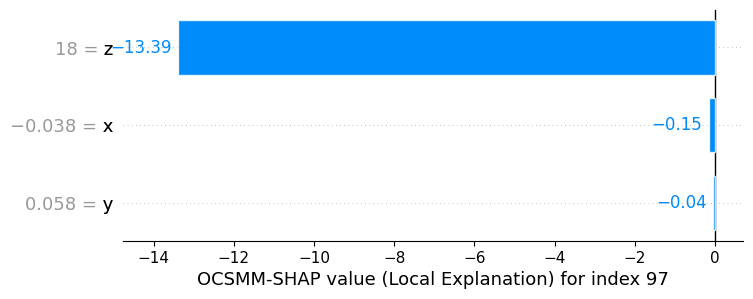

In [17]:
from src.utils.visualisation.deterministic_values import global_bar_plot_ocsmm, local_bar_plot_ocsmm
local_bar_plot_ocsmm(shapley_values.T.numpy(), 97, feature_names=['x', 'y', 'z'], datasets=dataset)

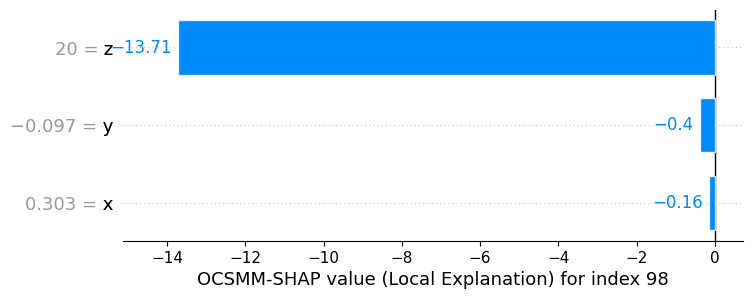

In [18]:
local_bar_plot_ocsmm(shapley_values.T.numpy(), 98, feature_names=['x', 'y', 'z'], datasets=dataset)

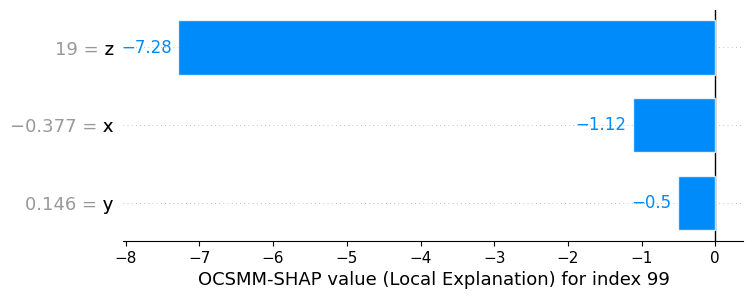

In [19]:
local_bar_plot_ocsmm(shapley_values.T.numpy(), 99, feature_names=['x', 'y', 'z'], datasets=dataset)

/tmp/ipykernel_3765131/3096737406.py:2: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  mean_abs_shap_values = np.abs(shapley_values.T).mean(axis=0)


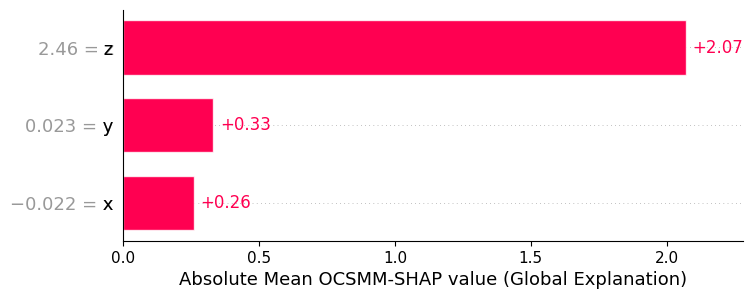

In [20]:
# global importance measure
mean_abs_shap_values = np.abs(shapley_values.T).mean(axis=0)  

# Call bar_plot for global explanation
global_bar_plot_ocsmm(mean_abs_shap_values.numpy(), feature_names=['x', 'y', 'z'], datasets=dataset)

SII needs atleast 4 features for 2nd order interaction, cannot't perform OCSMM-SHAP-IQ